# 과제 A. YOLO 서비스 — 사진을 넣으면 박스와 마스크를 보여 주는 노트북

이 노트북이 하는 일은 딱 두 가지예요.

| | 모델 | 무엇을 알려 주나 | 비유 |
|---|---|---|---|
| **탐지 (detect)** | `yolo26n.pt` | 이름 + **네모 박스** + 점수 | "여기쯤 사람이 있어!" 하고 손가락으로 가리키기 |
| **분할 (segment)** | `yolo26n-seg.pt` | 이름 + **윤곽을 따라 칠한 마스크** | 색연필로 사람 모양 그대로 색칠하기 |

**실행 방법:** 위에서부터 셀을 하나씩 `Shift + Enter`로 실행하세요. 핵심 코드는 `yolo_service.py`에 들어 있고, 노트북은 그 코드를 불러서 결과를 보여 줘요.

## 0단계. 준비 — 도구 불러오기
`yolo_service`는 우리가 만든 파일이에요. 그 안에 `detect()`(탐지), `segment()`(분할), `run()`(둘 다 돌리고 저장) 함수가 있어요.

In [1]:
import json
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import yolo_service as ys

plt.rcParams["font.family"] = "Malgun Gothic"   # 그래프 제목의 한글이 네모(□)로 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False

def show(*paths, titles=None, size=6):
    # 이미지 여러 장을 옆으로 나란히 보여 주는 도우미 함수
    fig, axes = plt.subplots(1, len(paths), figsize=(size * len(paths), size * 1.3))
    axes = [axes] if len(paths) == 1 else axes
    for ax, p, t in zip(axes, paths, titles or [Path(p).name for p in paths]):
        ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
        ax.set_title(t); ax.axis("off")
    plt.tight_layout(); plt.show()

print("설정:", "imgsz =", ys.IMGSZ, "| device =", ys.DEVICE)

설정: imgsz = 640 | device = cpu


## 1단계. 버스 사진으로 돌려 보기 (conf 0.25 와 0.50)

**conf(신뢰도 임계값)가 뭐예요?**
모델은 박스마다 "나 이거 이만큼 자신 있어" 하는 **점수(0~1)**를 붙여요.
conf는 **"이 점수보다 낮은 박스는 버려!" 하는 커트라인**이에요.
- 커트라인을 **낮추면**(0.25) → 박스가 많이 남아요 → 엉뚱한 것도 섞일 수 있어요 (**오탐**)
- 커트라인을 **높이면**(0.50) → 확실한 것만 남아요 → 진짜인데 버려지는 것도 생길 수 있어요 (**미탐**)

> ⚠️ 점수 0.9가 "10번 중 9번 맞는다"는 뜻은 아니에요. 그냥 **어떤 후보부터 볼지 정하는 순서표**라고 생각하세요.

In [2]:
IMAGE = "input/bus.jpg"
out_dir, dets, cmp = ys.run(IMAGE, confs=(0.25, 0.50))
print("결과 저장 위치:", out_dir)

결과 저장 위치: D:\aiffel\YOLO\outputs\yolo\bus


## 2단계. 탐지 결과 — 박스 · 클래스 · 점수

왼쪽은 원본, 가운데·오른쪽은 conf 0.25 / 0.50 결과예요.

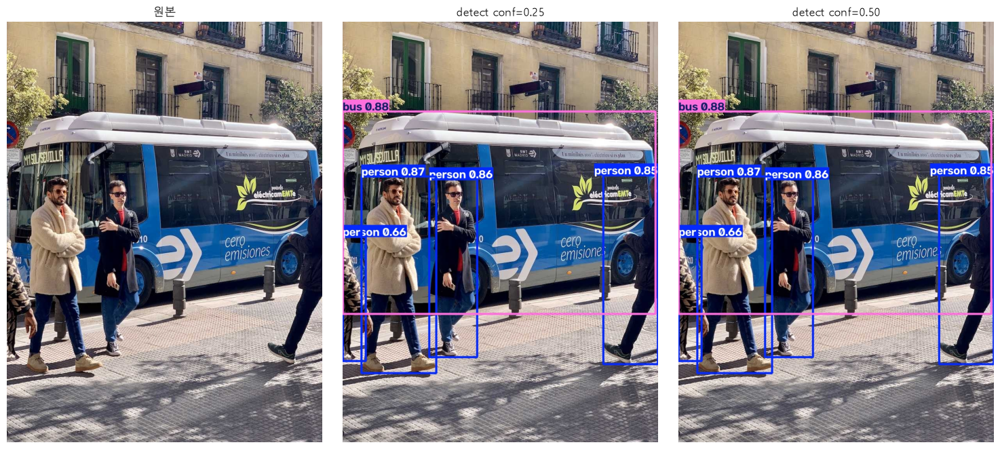

In [3]:
show(out_dir / "original.jpg", out_dir / "detect" / "conf0.25.jpg", out_dir / "detect" / "conf0.50.jpg",
     titles=["원본", "detect conf=0.25", "detect conf=0.50"], size=5)

### 그림이 "데이터"라는 걸 확인해 보기
그림 위 박스 하나는 JSON 파일 안의 **숫자 4개**예요. `box_xyxy_px = [x1, y1, x2, y2]`
- `(x1, y1)` = 박스 **왼쪽 위** 꼭짓점, `(x2, y2)` = **오른쪽 아래** 꼭짓점
- 단위는 **원본 사진의 픽셀**이에요 (0~1로 줄인 값이 아님). 사진 크기는 `image_size_hw`(높이, 너비)에 있어요.

In [4]:
det = json.loads((out_dir / "detect" / "conf0.25.json").read_text(encoding="utf-8"))
print("사진 크기 (높이, 너비):", det["image_size_hw"])
print("클래스별 개수:", det["count_by_class"])
print()
for d in det["detections"]:
    print(f"#{d['id']}  {d['class_name']:<8} 점수 {d['confidence']:.3f}  박스 {d['box_xyxy_px']}")

사진 크기 (높이, 너비): [1080, 810]
클래스별 개수: {'bus': 1, 'person': 4}

#0  bus      점수 0.881  박스 [0.0, 230.5, 803.2, 750.7]
#1  person   점수 0.872  박스 [48.6, 397.7, 240.3, 902.4]
#2  person   점수 0.861  박스 [222.9, 404.8, 345.5, 861.0]
#3  person   점수 0.846  박스 [669.6, 394.5, 809.9, 879.4]
#4  person   점수 0.656  박스 [0.2, 553.0, 59.7, 871.3]


**직접 연결해 보기:** 아래 셀은 JSON의 버스 박스 좌표 **숫자만 가지고** 원본 위에 직접 네모를 그려요.
그림의 `bus` 박스와 똑같은 자리에 그려지면 → "그림으로 보던 결과가 다른 프로그램도 읽을 수 있는 데이터"라는 증거예요.

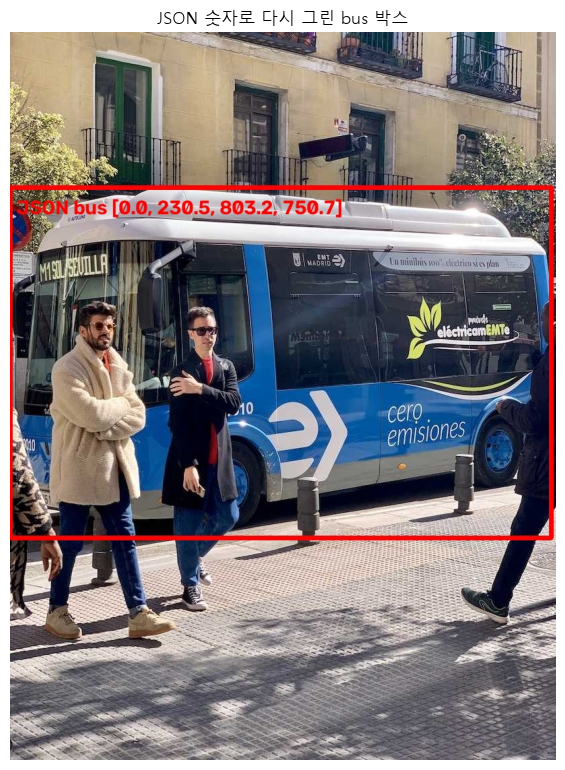

In [5]:
img = cv2.imread(str(out_dir / "original.jpg"))
bus = next(d for d in det["detections"] if d["class_name"] == "bus")
x1, y1, x2, y2 = map(int, bus["box_xyxy_px"])
cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 6)
cv2.putText(img, f"JSON bus {bus['box_xyxy_px']}", (x1 + 10, y1 + 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 3)
cv2.imwrite(str(out_dir / "checks" / "bus_box_from_json.jpg"), img)
show(out_dir / "checks" / "bus_box_from_json.jpg", titles=["JSON 숫자로 다시 그린 bus 박스"])

## 3단계. conf 0.25 → 0.50 : 무엇이 사라졌나?

규칙은 간단해요. **점수가 0.25 이상, 0.50 미만**인 박스가 0.50에서 사라져요.

In [6]:
print(f"conf {cmp['conf_low']}: {cmp['count_low']}개  →  conf {cmp['conf_high']}: {cmp['count_high']}개")
print("사라진 박스:", cmp["removed_when_raising_conf"] or "없음")
print("가장 낮은 점수:", min(d["confidence"] for d in det["detections"]))

conf 0.25: 5개  →  conf 0.5: 5개
사라진 박스: 없음
가장 낮은 점수: 0.6562


**결과가 똑같다면?** 이상한 게 아니에요! 버스 사진은 모든 박스 점수가 0.50보다 높아서 둘 다 통과했어요.
그럼 0.25 밑에는 아무 후보도 없었을까요? 커트라인을 확 낮춰서 "버려지던 후보"를 구경해 봐요.

In [7]:
_, low = ys.detect(IMAGE, conf=0.05)
for d in low["detections"]:
    mark = "  ← 0.25에서 이미 버려짐" if d["confidence"] < 0.25 else ""
    print(f"{d['class_name']:<10} {d['confidence']:.3f}{mark}")

bus        0.881
person     0.872
person     0.861
person     0.846
person     0.656
stop sign  0.128  ← 0.25에서 이미 버려짐
handbag    0.076  ← 0.25에서 이미 버려짐
skateboard 0.071  ← 0.25에서 이미 버려짐
handbag    0.053  ← 0.25에서 이미 버려짐


📝 **관찰 기록 (bus, 탐지)**
- **0.25 → 0.50에서 사라진 것: 없음.** 5개 박스의 점수가 모두 0.656 이상이라 두 커트라인을 다 통과했어요.
- **0.25 아래에 숨어 있던 오탐 후보:** `stop sign 0.13` (박스 x 0~35, y 252~326). 원본을 보면 **정지 표지판이 아니라 주차금지 표지판**이에요.
  conf 0.25가 이 오탐을 이미 걸러 주고 있었어요. 나머지 `handbag 0.08`, `skateboard 0.07`도 해당 위치에 그런 물체가 없어요.
- **미탐:** 원본과 대조했을 때 보이는 사람 4명(왼쪽 끝에 잘린 사람 포함)과 버스 1대를 모두 찾았어요.

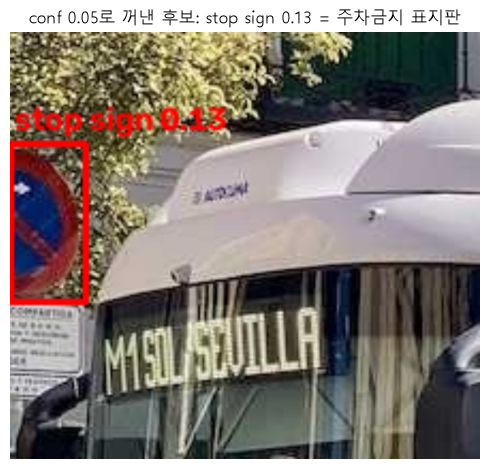

In [8]:
show(out_dir / "checks" / "stop_sign_false_positive.jpg", titles=["conf 0.05로 꺼낸 후보: stop sign 0.13 = 주차금지 표지판"], size=5)

## 4단계. 분할 결과 — 마스크

**마스크 = 흑백 그림**이에요. 대상인 픽셀은 **흰색(255)**, 아닌 픽셀은 **검은색(0)**.
대상 1개마다 마스크 파일 1장이 `masks/` 폴더에 저장돼요. 아래는 원본 위에 마스크를 **반투명 색**으로 겹친 그림이에요.

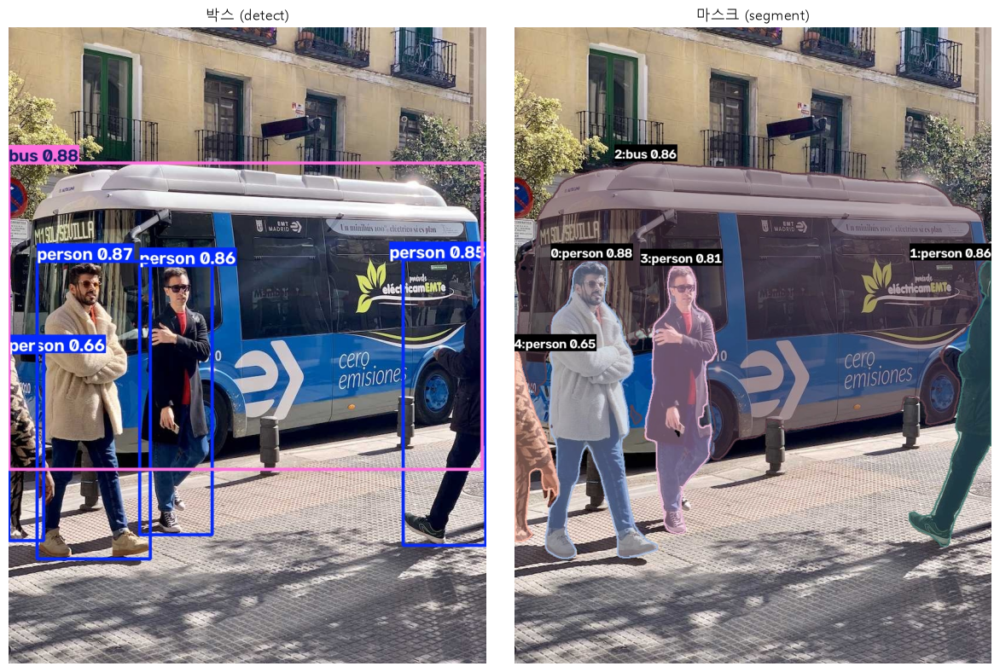

In [9]:
show(out_dir / "detect" / "conf0.25.jpg", out_dir / "segment" / "conf0.25.jpg",
     titles=["박스 (detect)", "마스크 (segment)"], size=6)

### 박스 안에는 배경이 얼마나 섞여 있었을까?
`mask_over_box` = 마스크 픽셀 수 ÷ 박스 픽셀 수
- 1.0에 가까우면 → 박스가 대상에 꽉 맞음
- 0.3이면 → **박스의 70%는 배경**이었다는 뜻! (팔다리를 벌린 사람은 박스 안에 빈 공간이 많아요)

이게 수업에서 말한 **"위치 찾기는 박스로 충분, 면적 재기는 마스크가 필요"**의 이유예요.

In [10]:
seg = json.loads((out_dir / "segment" / "conf0.25.json").read_text(encoding="utf-8"))
print(f"{'id':<3}{'class':<8}{'점수':>7}{'박스 px':>10}{'마스크 px':>11}{'마스크/박스':>10}")
for o in seg["objects"]:
    print(f"{o['id']:<3}{o['class_name']:<8}{o['confidence']:>7.3f}{o['box_area_px']:>10,}{o['mask_area_px']:>11,}{o['mask_over_box']:>10.2f}")

id class        점수     박스 px     마스크 px    마스크/박스
0  person    0.877    97,049     49,302      0.51
1  person    0.863    68,096     21,311      0.31
2  bus       0.856   410,221    255,375      0.62
3  person    0.811    56,022     33,411      0.60
4  person    0.648    23,681     11,100      0.47


> 💡 탐지 모델과 분할 모델은 **서로 다른 모델**이라 같은 사람이라도 점수와 번호(id)가 조금 달라요. 비교할 때는 번호가 아니라 **위치**로 짝지어 보세요.

### 저장된 마스크 파일 다시 열어 보기
화면에 칠해진 색이 진짜로 저장된 파일과 같은지 확인해요. (흰색 = 대상)

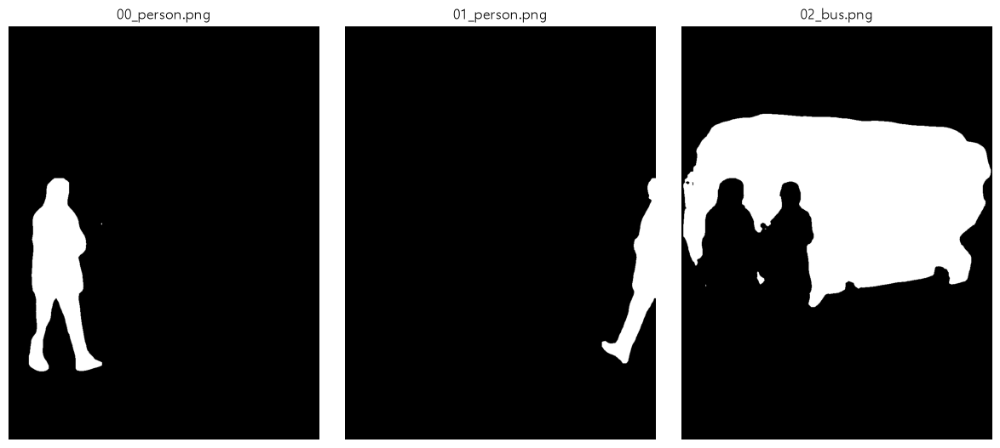

In [11]:
mask_files = [out_dir / o["mask_file"] for o in seg["objects"]]
show(*mask_files[:3], titles=[Path(m).name for m in mask_files[:3]], size=4)

### 윤곽이 어긋난 곳 확대해 보기
대상끼리 **겹친 곳**, **그림자가 짙은 곳**, **사진 가장자리에 잘린 사람**을 확대하면 실수를 찾기 쉬워요.
아래 `x1, y1, x2, y2`를 바꿔 가며 원하는 곳을 확대해 보세요.

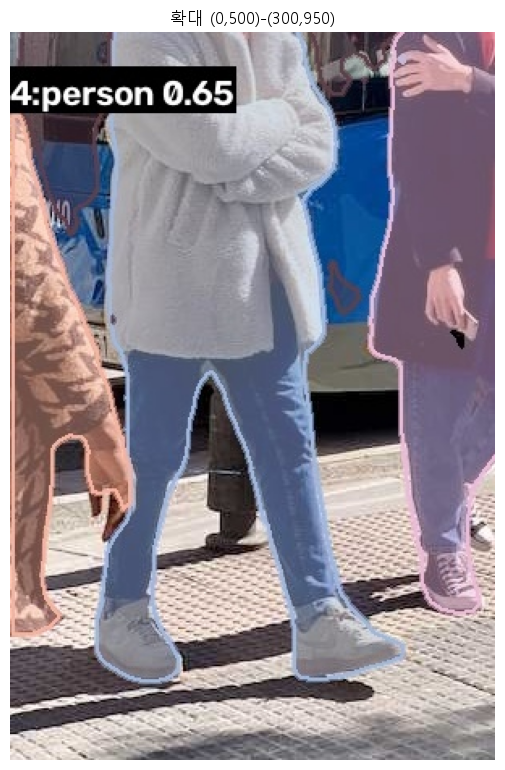

In [12]:
x1, y1, x2, y2 = 0, 500, 300, 950     # ← 확대할 영역 (왼쪽 아래 사람들 근처)
seg_img = cv2.imread(str(out_dir / "segment" / "conf0.25.jpg"))
crop = seg_img[y1:y2, x1:x2]
cv2.imwrite(str(out_dir / "checks" / "zoom.jpg"), crop)
show(out_dir / "checks" / "zoom.jpg", titles=[f"확대 ({x1},{y1})-({x2},{y2})"])

📝 **관찰 기록 (bus, 분할)**
- **마스크에서 빠진 부분:** 3번 사람(선글라스, 0.81)의 **휴대폰을 쥔 손 바로 아래 어두운 코트 부분**에 마스크 구멍이 있어요.
  위치는 x 271~282, y 683~697 (약 11×14 픽셀)이에요. 사람 몸인데 배경으로 판단한 거예요. 아래 확대 그림에서 왼쪽이 원본, 오른쪽이 마스크예요.
- **박스와 마스크 차이:** 오른쪽 끝에서 걷는 사람은 `마스크 ÷ 박스 = 0.31`이에요. 다리를 벌리고 걸어서 **박스의 69%가 배경**이에요.
  이 사람의 넓이를 박스로 재면 약 3배로 부풀려져요.
- **잘 된 부분:** 오른쪽 사람 뒤의 볼라드(길가 기둥)는 버스 마스크에서 정확히 빠져 있어요.

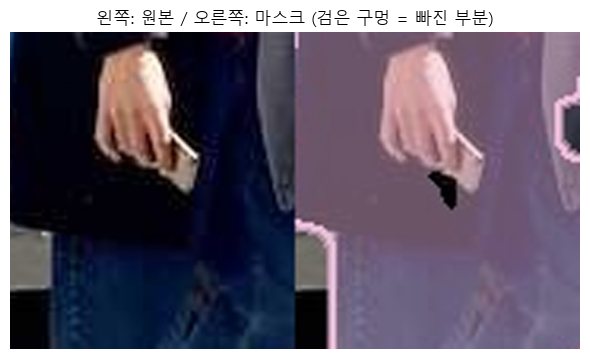

In [13]:
show(out_dir / "checks" / "phone_missing_from_mask.jpg", titles=["왼쪽: 원본 / 오른쪽: 마스크 (검은 구멍 = 빠진 부분)"], size=6)

## 5단계. 내 사진으로 바꿔서 돌려 보기
1. 공개해도 되는(얼굴·개인정보·회사 기밀이 없는) 사진을 `input/` 폴더에 넣어요.
2. 아래 `MY_PHOTOS` 목록에 파일 이름을 넣고 실행해요. 여러 장도 돼요.
3. 결과는 사진마다 `outputs/yolo/<사진이름>/` 폴더에 따로 저장돼요. 휴대폰 사진은 커서 한 장에 몇 초씩 걸려요.
4. `manifest.json`의 `input_source`에 **사진 출처와 공유 동의 여부**를 꼭 적어 주세요.
5. 🔒 **얼굴·번호판 가리기**: `privacy_regions.json`에 사진별로 가릴 영역 좌표를 적어 두면, 저장되는 결과 그림에 자동으로 모자이크가 들어가요.
   모델에는 **원본을 그대로** 넣기 때문에 탐지·분할 결과(점수·좌표)는 바뀌지 않아요. 원본 사진(`input/`)은 제출하지 않아요.

> 확인할 수 있는 대상은 COCO 80개 클래스뿐이에요 (person, car, dog, cup, chair …). 바로 아래 셀에서 목록을 볼 수 있어요.

In [14]:
print(ys.load_model("yolo26n.pt").names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

 input/20161029_194728.jpg → D:\aiffel\YOLO\outputs\yolo\20161029_194728
  conf 0.25: 3개 {'car': 3}
  conf 0.5: 2개 {'car': 2}
  0.25 → 0.50 에서 사라진 박스: [('car', 0.4128)]


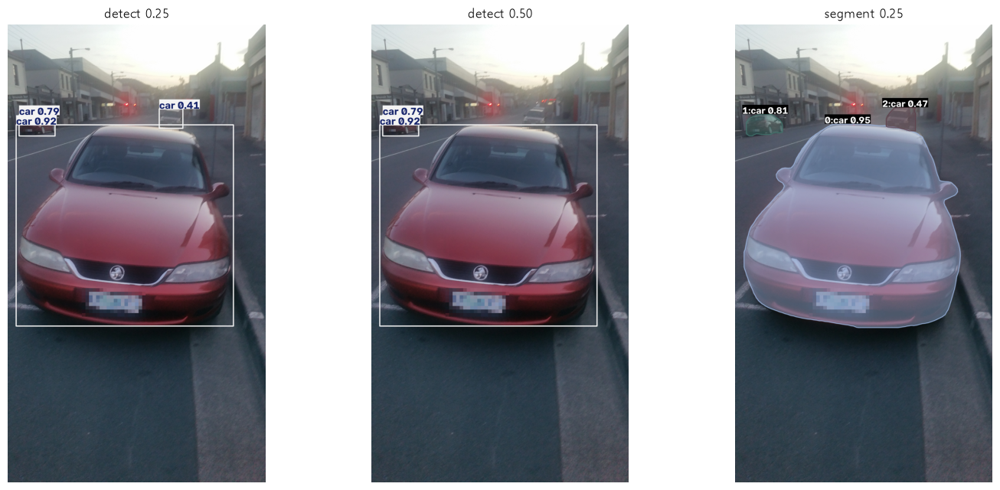

 input/20180309_190421.jpg → D:\aiffel\YOLO\outputs\yolo\20180309_190421
  conf 0.25: 11개 {'person': 8, 'dining table': 1, 'cell phone': 1, 'bowl': 1}
  conf 0.5: 5개 {'person': 4, 'dining table': 1}
  0.25 → 0.50 에서 사라진 박스: [('person', 0.4934), ('cell phone', 0.378), ('person', 0.3665), ('person', 0.3555), ('bowl', 0.3034), ('person', 0.25)]


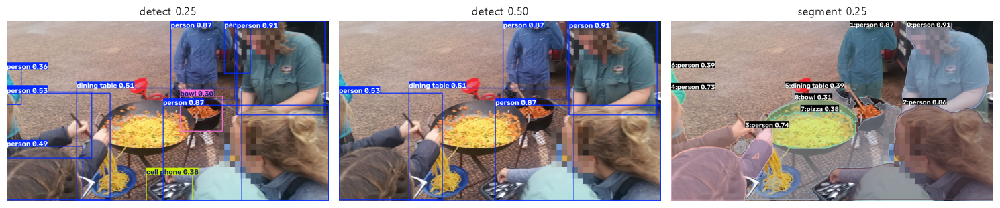

In [15]:
MY_PHOTOS = ["input/20161029_194728.jpg", "input/20180309_190421.jpg"]   # ← 내 사진 파일 이름들

for photo in MY_PHOTOS:
    if not Path(photo).exists():
        print(f"{photo} 파일이 없어요. input/ 폴더에 사진을 넣고 다시 실행하세요."); continue
    my_dir, my_dets, my_cmp = ys.run(photo, confs=(0.25, 0.50))
    print("=" * 60, "\n", photo, "→", my_dir)
    for conf, d in my_dets.items():
        print(f"  conf {conf}: {len(d['detections'])}개 {d['count_by_class']}")
    print("  0.25 → 0.50 에서 사라진 박스:",
          [(d["class_name"], d["confidence"]) for d in my_cmp["removed_when_raising_conf"]] or "없음")
    show(my_dir / "detect" / "conf0.25.jpg", my_dir / "detect" / "conf0.50.jpg", my_dir / "segment" / "conf0.25.jpg",
         titles=["detect 0.25", "detect 0.50", "segment 0.25"], size=5)

In [16]:
# 사진별 결과를 한눈에: outputs/yolo/summary.json
for row in ys.write_summary():
    print(row["image"], "| 0.25:", row["conf0.25"]["detect"], "| 0.50:", row["conf0.50"]["detect"])
    print("     사라진 박스:", row["removed_when_raising_conf"] or "없음")

20161029_194728 | 0.25: {'car': 3} | 0.50: {'car': 2}
     사라진 박스: [('car', 0.4128)]
20180309_190421 | 0.25: {'person': 8, 'dining table': 1, 'cell phone': 1, 'bowl': 1} | 0.50: {'person': 4, 'dining table': 1}
     사라진 박스: [('person', 0.4934), ('cell phone', 0.378), ('person', 0.3665), ('person', 0.3555), ('bowl', 0.3034), ('person', 0.25)]
bus | 0.25: {'bus': 1, 'person': 4} | 0.50: {'bus': 1, 'person': 4}
     사라진 박스: 없음


## 5-1. 내 사진 원본 대조 기록
확인용 확대 그림은 `make_checks.py`로 만들었고 `outputs/yolo/<사진이름>/checks/`에 있어요. 모든 그림에 얼굴·번호판 모자이크가 들어가 있어요.

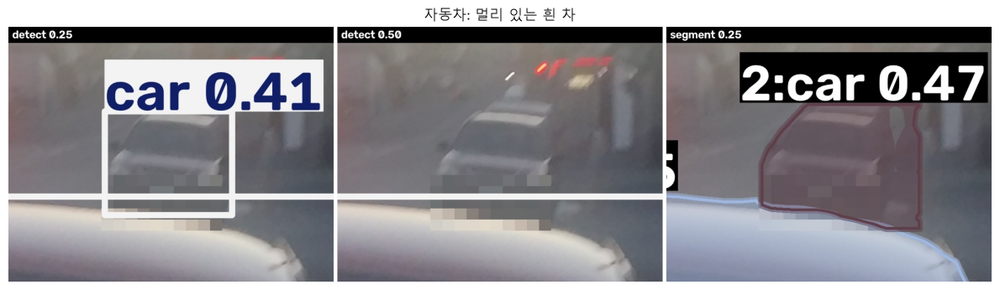

In [17]:
CAR, FOOD = Path("outputs/yolo/20161029_194728"), Path("outputs/yolo/20180309_190421")
show(CAR / "checks" / "far_car_conf025_vs_conf050_vs_mask.jpg", titles=["자동차: 멀리 있는 흰 차"], size=12)

📝 **관찰 기록 (자동차 사진)**
- **미탐 (conf 0.50):** 멀리 있는 흰 차는 **진짜 차**예요. 그런데 탐지 점수가 0.41이라 **conf 0.50에서 사라져요**.
  "차가 몇 대인가?"를 묻는 일이라면 0.50은 차를 놓치는 커트라인이에요.
- **마스크가 배경까지 칠함:** 같은 차의 분할 마스크(0.47)는 차체 오른쪽 바깥의 **배경(세로로 긴 부분)까지 칠했어요**.
  탐지 박스 오른쪽 끝은 x 2032인데 분할 박스는 x 2096까지 가요. 멀고 흐린 물체라 경계가 퍼진 것으로 보여요.
- **분할 점수는 탐지 점수와 달라요:** 같은 차인데 탐지는 0.41, 분할은 0.47이에요. 두 모델은 따로 판단해요.

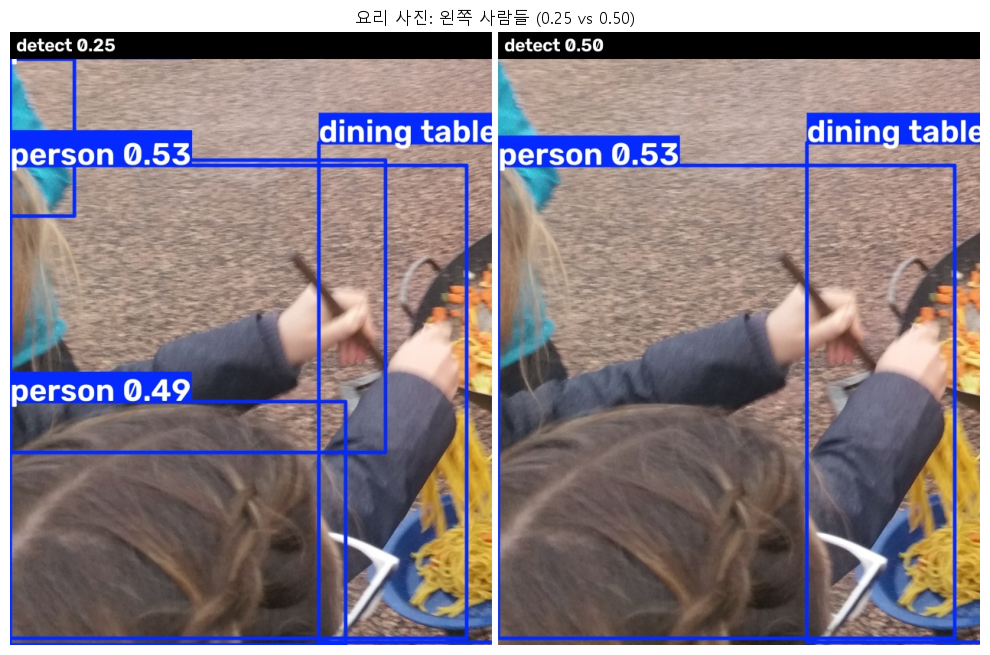

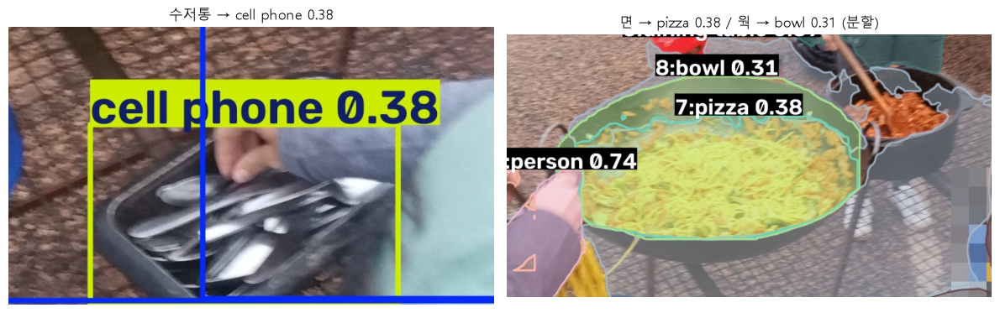

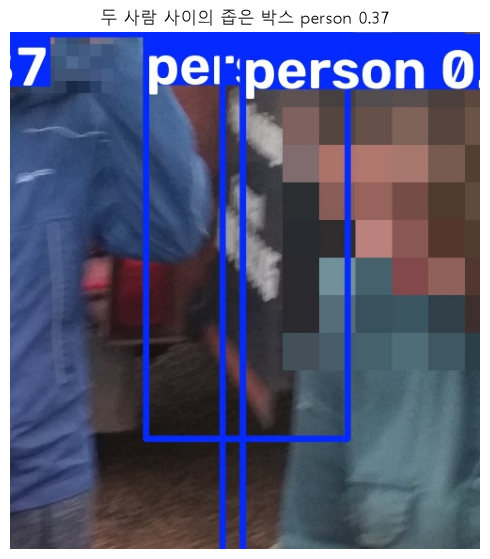

In [18]:
show(FOOD / "checks" / "left_people_conf025_vs_conf050.jpg", titles=["요리 사진: 왼쪽 사람들 (0.25 vs 0.50)"], size=10)
show(FOOD / "checks" / "tray_as_cell_phone.jpg", FOOD / "checks" / "wok_as_pizza_and_bowl.jpg",
     titles=["수저통 → cell phone 0.38", "면 → pizza 0.38 / 웍 → bowl 0.31 (분할)"], size=6)
show(FOOD / "checks" / "narrow_person_box_between_two.jpg", titles=["두 사람 사이의 좁은 박스 person 0.37"], size=5)

📝 **관찰 기록 (야외 요리 사진)**
- **오탐:** 수저가 담긴 통을 `cell phone 0.38`로 탐지했어요 (박스 x 2302~3064, y 2542~2988).
- **클래스 한계 (오탐):** 분할 모델은 웍 위의 면을 `pizza 0.38`, 웍을 `bowl 0.31`로 봤어요. 탐지 모델은 냄비를 `bowl 0.30`으로 봤어요.
  COCO 80개 클래스에 **면 요리·웍·냄비가 없어서** 가장 비슷한 이름을 고른 거예요. 모델이 배운 적 없는 물체는 맞힐 수 없어요.
- **미탐 (conf 0.50):** 왼쪽 아래 뒤통수만 보이는 사람(0.49)과 왼쪽 끝 청록색 옷의 사람(0.36)은 **진짜 사람**인데 conf 0.50에서 사라져요.
  사진 가장자리에 잘리거나 뒤를 보는 사람은 점수가 낮게 나와요.
- **확인 필요:** 파란 재킷과 초록 셔츠 사람 사이의 **좁은 박스 `person 0.37`** (x 3589~4018, y 2~866)은 별도의 사람이 보이지 않아요.
  옆 사람 팔이나 뒤쪽 트럭 일부를 사람으로 본 **중복·오탐으로 추정**하지만, 원본만으로 확정하기 어려워 '확인 필요'로 남겨요.
  `person 0.25`(x 2~1402, y 1177~2269)도 `person 0.53` 박스와 대부분 겹쳐서 같은 사람의 중복으로 보여요 (확인 필요).
- **두 모델 차이:** conf 0.25에서 탐지는 사람 8명, 분할은 6명을 찾았어요. 같은 사진·같은 커트라인이라도 모델마다 결과가 달라요.

## 6단계. (여유가 있다면) 슬라이더로 conf 바꿔 보기
슬라이더를 움직이면 그 커트라인으로 다시 탐지해서 보여 줘요. 파일은 저장하지 않아요(구경용).

In [19]:
import ipywidgets as W
from IPython.display import display

slider = W.FloatSlider(value=0.25, min=0.05, max=0.95, step=0.05, description="conf")
picker = W.Text(value=IMAGE, description="사진")
out = W.Output()

def update(*_):
    with out:
        out.clear_output(wait=True)
        if not Path(picker.value).exists():
            print("파일 없음:", picker.value); return
        r, d = ys.detect(picker.value, slider.value)
        plt.figure(figsize=(6, 8)); plt.imshow(r.plot()[..., ::-1]); plt.axis("off")
        plt.title(f"conf={slider.value:.2f} → {len(d['detections'])}개 {d['count_by_class']}"); plt.show()

slider.observe(update, "value"); picker.observe(update, "value")
display(W.VBox([picker, slider, out])); update()

## 7단계. 기록 확인 — manifest.json
"다른 사람이 똑같이 다시 돌릴 수 있게" 무엇을, 어디서, 어떤 버전으로 돌렸는지 적어 둔 파일이에요.

In [20]:
print((out_dir / "manifest.json").read_text(encoding="utf-8"))

{
  "created_at": "2026-11-10T19:21:33",
  "input_file": "input/bus.jpg",
  "input_source": "bus.jpg: https://ultralytics.com/images/bus.jpg (Ultralytics 예제)",
  "input_size_hw": [
    1080,
    810
  ],
  "privacy": {
    "exif_gps": "출력 이미지는 OpenCV로 다시 저장해 EXIF(GPS 포함)가 들어가지 않음",
    "mosaic_regions": [],
    "mosaic_applies_to": "저장된 결과 그림(original/detect/segment jpg)에만 적용. 모델 입력과 JSON 좌표·마스크는 원본 기준",
    "original_input_submitted": null
  },
  "models": {
    "detect": "models/yolo26n.pt",
    "segment": "models/yolo26n-seg.pt"
  },
  "packages": {
    "python": "3.14.0",
    "ultralytics": "8.4.208",
    "torch": "2.15.0+cpu",
    "opencv": "5.0.0",
    "numpy": "2.5.4"
  },
  "run_location": {
    "where": "local",
    "os": "Windows 11",
    "venv": "D:/aiffel/YOLO/.venv/Scripts/python.exe"
  },
  "settings": {
    "imgsz": 640,
    "device": "cpu",
    "conf": [
      0.25,
      0.5
    ]
  },
  "code": "yolo_service.py",
  "outputs": [
    "original.jpg",
    "detect/conf0.25